In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter, FuncFormatter
from pathlib import Path

ROOT = Path("/Users/shraddha/Documents/DATA_SCIENCE/Shellscope/shellscope")
DATA = ROOT / "data" / "processed"
FIG  = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="talk", font_scale=0.8)
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
    "savefig.dpi": 200, "savefig.bbox": "tight",
})
COLORS = {"main": "#534AB7", "light": "#C9C5EE", "accent": "#D85A30",
          "Glasgow (G)": "#1D9E75", "Rest of UK": "#534AB7"}
SOURCE = "Source: Companies House Basic Company Data, snapshot 1 Oct 2026."

def add_source(fig, note=""):
    fig.text(0.01, -0.01, SOURCE + (" " + note if note else ""),
             fontsize=9, color="gray", ha="left", va="top")

def save(fig, name):
    fig.savefig(FIG / name)
    print("saved:", name)

In [2]:
SIC_NAMES = {"A": "Agriculture", "B": "Mining", "C": "Manufacturing", "D": "Energy supply",
             "E": "Water & waste", "F": "Construction", "G": "Wholesale & retail", "H": "Transport",
             "I": "Hotels & food", "J": "Info & comms", "K": "Finance & insurance", "L": "Real estate",
             "M": "Professional services", "N": "Admin & support", "O": "Public admin", "P": "Education",
             "Q": "Health & social", "R": "Arts & recreation", "S": "Other services",
             "T": "Households", "U": "Extraterritorial"}

cols = ["IncorporationDate", "glasgow", "in_scope", "is_active",
        "accounts_overdue", "sic_section", "company_age_years"]
df = pd.read_parquet(DATA / "shellscope_companies.parquet", columns=cols)

# Chart A: company age
age = df.loc[df["company_age_years"] > 0, "company_age_years"].dropna()

# Chart B: overdue rate by industry (pre-aggregated, with 95% CI)
od = df.loc[df["in_scope"] & df["is_active"], ["sic_section", "accounts_overdue"]].copy()
od["overdue"] = od["accounts_overdue"].astype(int)
od["industry"] = od["sic_section"].astype(str).map(lambda s: SIC_NAMES.get(s, s))
ind = od.groupby("industry")["overdue"].agg(rate="mean", n="count")
ind = ind[ind["n"] >= 1000].sort_values("rate")
ind["ci"] = 1.96 * np.sqrt(ind["rate"] * (1 - ind["rate"]) / ind["n"])
overall = od["overdue"].mean()

# Charts C and D: monthly trend, and Glasgow vs UK indexed
inc = df.loc[(df["IncorporationDate"] >= "2000-01-01") & (df["IncorporationDate"] < "2026-10-01"),
             ["IncorporationDate", "glasgow"]].copy()
monthly = inc.set_index("IncorporationDate").resample("MS").size()
roll = monthly.rolling(12).mean()
inc["region"] = np.where(inc["glasgow"].fillna(False).astype(bool), "Glasgow (G)", "Rest of UK")
m = pd.crosstab(inc["IncorporationDate"].dt.to_period("M"), inc["region"])
m.index = m.index.to_timestamp()
m = m.asfreq("MS", fill_value=0)
idx = 100 * m.rolling(12).mean() / m.loc["2015"].mean()

print(len(age), ind.tail(3).round(4), round(overall, 4), len(monthly), idx.tail(1).round(1), sep="\n")

5704710
                 rate      n      ci
industry                            
Mining         0.0492   7402  0.0049
Energy supply  0.0580  16507  0.0036
None supplied  0.1035  50974  0.0026
0.0188
321
region             Glasgow (G)  Rest of UK
IncorporationDate                         
2026-09-01               431.6       436.9


In [8]:
cat = df["CompanyCategory"].value_counts()
cat = cat[cat > 0]
print(cat)

top = cat.head(7)
other = cat.iloc[7:].sum()
plot = pd.concat([pd.Series({f"Other ({len(cat) - 7} types)": other}), top.sort_values()])
share = plot / plot.sum()

fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.barh(plot.index.astype(str), plot.values / 1e6, color="#534AB7", height=0.65)
ax.bar_label(bars, labels=[f"{v/1e6:.2f}M  ({s:.1%})" for v, s in zip(plot.values, share.values)],
             padding=4, fontsize=9)
ax.set_title(f"{top.index[0]} make up {top.iloc[0]/cat.sum():.0%} of the UK register "
             f"({cat.sum()/1e6:.1f}M entities)")
ax.set_xlabel("Number of entities (millions)")
ax.set_xlim(0, plot.max() / 1e6 * 1.25)
ax.spines[["top", "right"]].set_visible(False)
fig.savefig(FIG / "eda_01_company_types.png", dpi=200, bbox_inches="tight")
plt.show()

KeyError: 'CompanyCategory'

In [3]:
def plot_trend(ax, monthly, roll):
    ax.plot(monthly.index, monthly.values, color=COLORS["light"], lw=1, label="per month")
    ax.plot(roll.index, roll.values, color=COLORS["main"], lw=2.5, label="12-month average")
    for d, txt, h in [("2020-03-23", "COVID lockdown", 0.95), ("2025-11-18", "ID verification", 0.80)]:
        d = pd.Timestamp(d)
        ax.axvline(d, color=COLORS["accent"], ls="--", lw=1.4)
        ax.annotate(txt, xy=(d, monthly.max() * h), xytext=(-5, 0), textcoords="offset points",
                    ha="right", fontsize=10, color=COLORS["accent"])
    ax.xaxis.set_major_locator(mdates.YearLocator(4))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.set(ylabel="companies per month", xlabel="")
    ax.set_title(f"Incorporations now ~{roll.iloc[-1]/1000:.0f}k a month "
                 f"(vs ~{roll.loc['2005-12-01']/1000:.0f}k in 2005)")
    ax.legend(loc="upper left", fontsize=10)

def plot_glasgow(ax, idx):
    for reg in ["Rest of UK", "Glasgow (G)"]:
        ax.plot(idx.index, idx[reg], color=COLORS[reg], lw=2.2, label=reg)
    ax.axhline(100, color="gray", ls=":", lw=1)
    ax.xaxis.set_major_locator(mdates.YearLocator(4))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    g, u = idx["Glasgow (G)"].iloc[-1], idx["Rest of UK"].iloc[-1]
    ax.set(ylabel="index (2015 = 100)", xlabel="")
    ax.set_title(f"Since 2015: Glasgow {g-100:+.0f}% vs rest of UK {u-100:+.0f}%")
    ax.legend(loc="upper left", fontsize=10)

def plot_industry(ax, ind, overall):
    colors = [COLORS["accent"] if r == ind["rate"].max() else COLORS["light"] for r in ind["rate"]]
    ax.barh(ind.index, ind["rate"], xerr=ind["ci"], color=colors, height=0.7,
            error_kw=dict(ecolor="#444", lw=1, capsize=2))
    ax.axvline(overall, color="#222", ls="--", lw=1.2)
    ax.text(overall, -0.9, f" all: {overall:.1%}", fontsize=10, va="top")
    ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=1))
    ax.tick_params(axis="y", labelsize=10)
    ax.set(xlabel="active companies with overdue accounts (95% CI)", ylabel="")
    ax.set_title(f"Highest overdue rate: {ind.index[-1]} ({ind['rate'].iloc[-1]:.1%})")

def plot_age(ax, age):
    bins = np.logspace(np.log10(age.min()), np.log10(age.max()), 60)
    ax.hist(age, bins=bins, color=COLORS["main"], edgecolor="white", linewidth=0.3)
    ax.set_xscale("log")
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    med = age.median()
    ax.axvline(med, color=COLORS["accent"], lw=2)
    ax.set(xlabel="company age (years, log scale)", ylabel="companies")
    ax.set_title(f"Half of companies are under {med:.1f} years old")

saved: final_06_trend.png


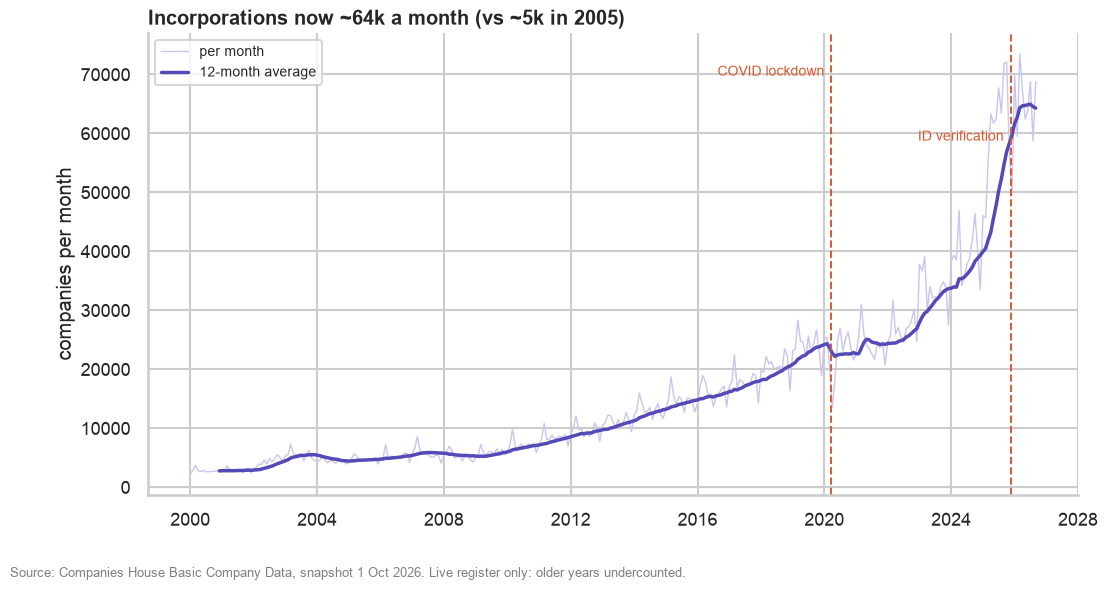

saved: final_07_glasgow_vs_uk.png


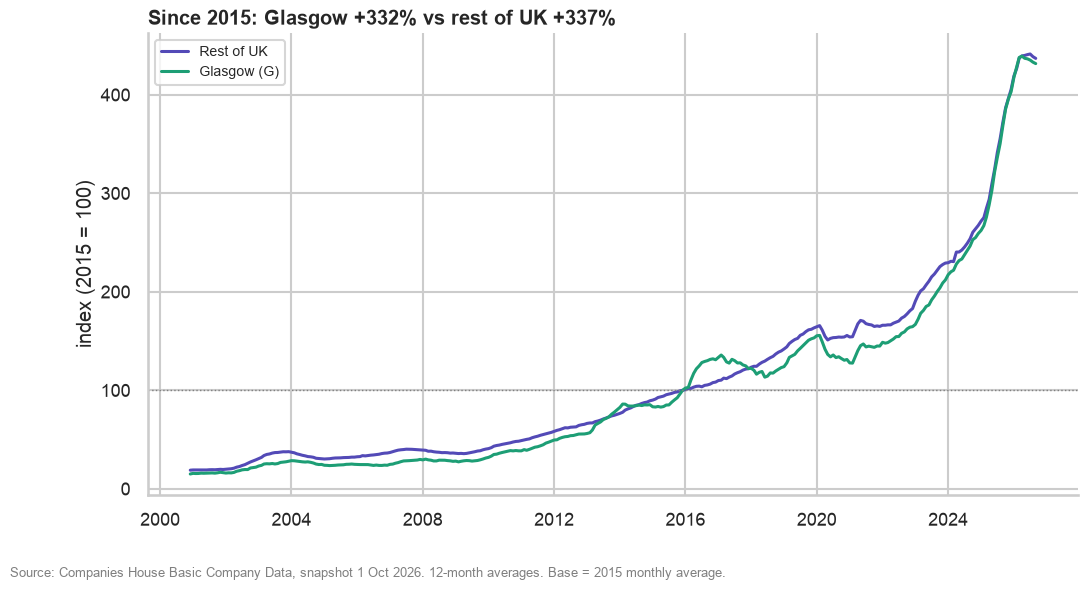

saved: final_04_overdue_by_industry.png


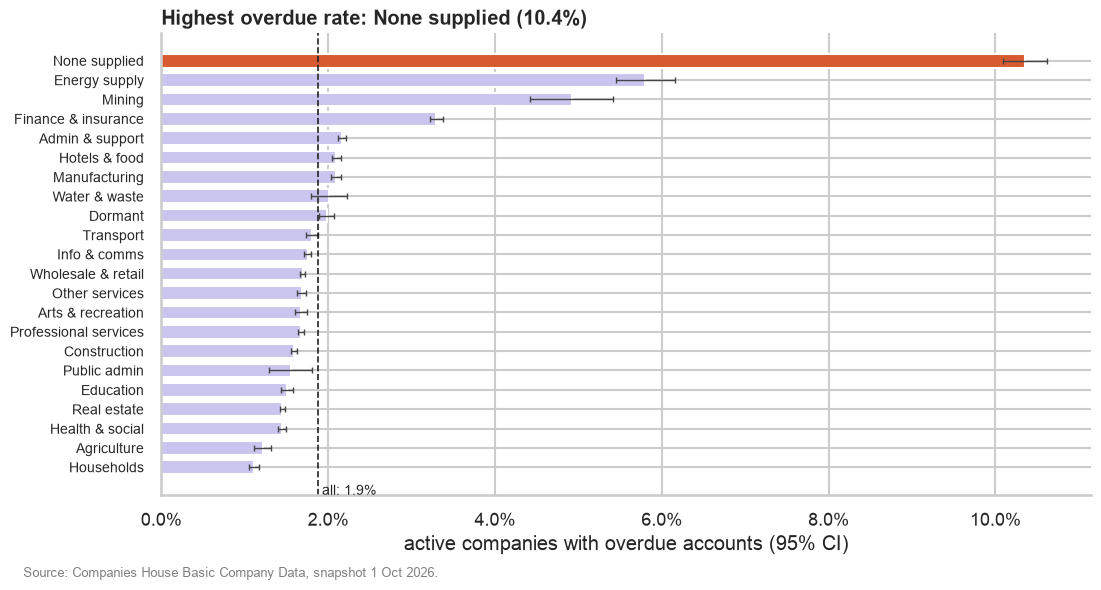

saved: final_03_company_age.png


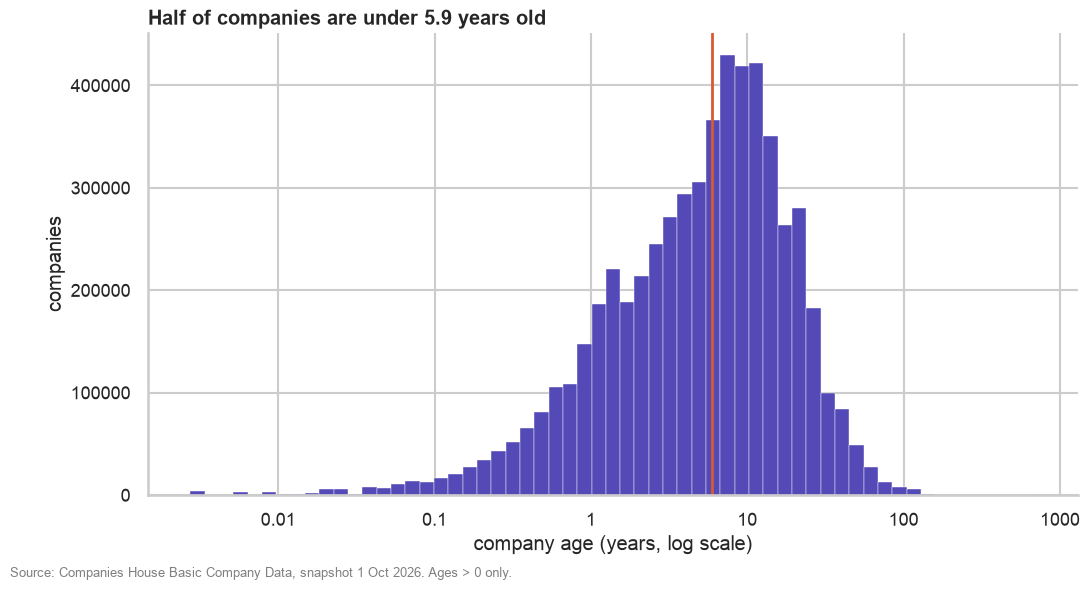

saved: eda_08_summary_2x2.png


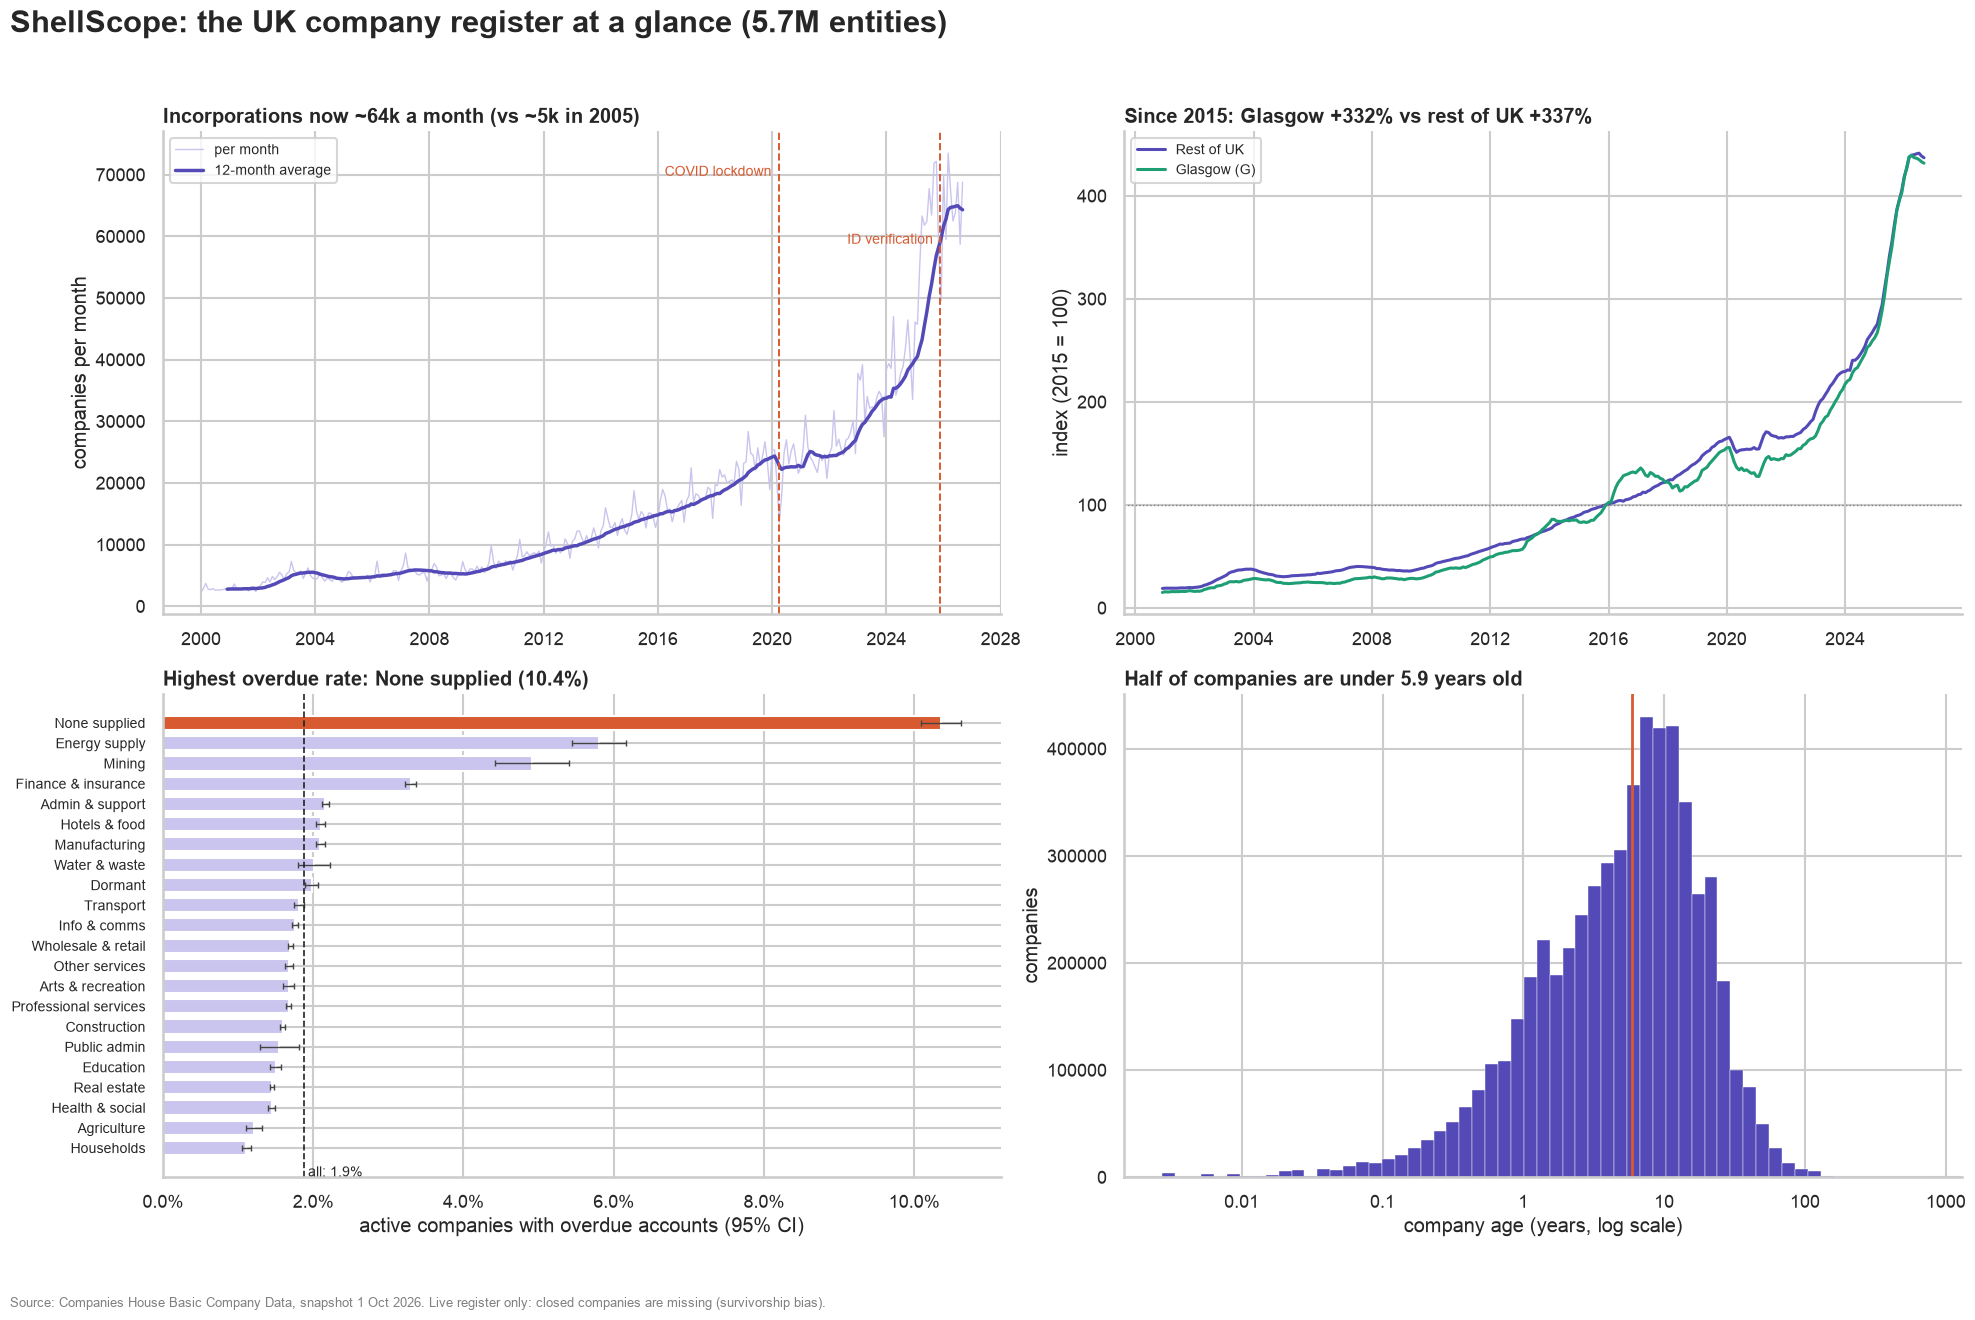

In [4]:
jobs = [("final_06_trend.png", plot_trend, (monthly, roll), "Live register only: older years undercounted."),
        ("final_07_glasgow_vs_uk.png", plot_glasgow, (idx,), "12-month averages. Base = 2015 monthly average."),
        ("final_04_overdue_by_industry.png", plot_industry, (ind, overall), ""),
        ("final_03_company_age.png", plot_age, (age,), "Ages > 0 only.")]
for name, func, args, note in jobs:
    fig, ax = plt.subplots(figsize=(12, 6))
    func(ax, *args)
    add_source(fig, note)
    save(fig, name)
    plt.show()

fig, axes = plt.subplots(2, 2, figsize=(20, 13))
plot_trend(axes[0, 0], monthly, roll)
plot_glasgow(axes[0, 1], idx)
plot_industry(axes[1, 0], ind, overall)
plot_age(axes[1, 1], age)
fig.suptitle("ShellScope: the UK company register at a glance (5.7M entities)",
             x=0.01, ha="left", fontsize=22, weight="bold")
fig.tight_layout(rect=(0, 0.02, 1, 0.96))
add_source(fig, "Live register only: closed companies are missing (survivorship bias).")
save(fig, "eda_08_summary_2x2.png")
plt.show()

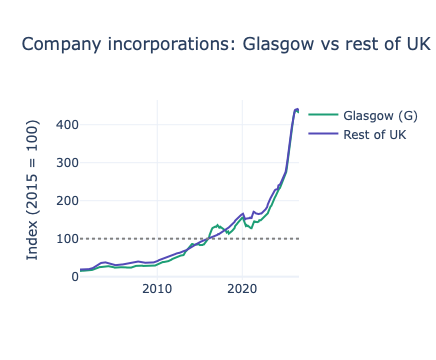

saved: /Users/shraddha/Documents/DATA_SCIENCE/Shellscope/shellscope/reports/interactive_glasgow_vs_uk.html


In [6]:
import plotly.express as px     # if missing: %pip install plotly, then restart the kernel

long = (idx.reset_index()
           .melt(id_vars="IncorporationDate", var_name="region", value_name="index")
           .dropna())
pfig = px.line(long, x="IncorporationDate", y="index", color="region",
               color_discrete_map={r: COLORS[r] for r in ["Glasgow (G)", "Rest of UK"]},
               labels={"IncorporationDate": "", "index": "Index (2015 = 100)", "region": ""},
               title="Company incorporations: Glasgow vs rest of UK (12-month average, 2015 = 100)")
pfig.add_hline(y=100, line_dash="dot", line_color="gray")
pfig.update_layout(template="plotly_white", hovermode="x unified")
out = ROOT / "reports" / "interactive_glasgow_vs_uk.html"
pfig.write_html(out, include_plotlyjs="cdn")
pfig.show()
print("saved:", out)

In [2]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path("/Users/shraddha/Documents/DATA_SCIENCE/Shellscope/shellscope")
DATA = ROOT / "data" / "processed"
FIG  = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

df = pd.read_parquet(DATA / "shellscope_companies.parquet",
                     columns=["CompanyNumber", "CompanyCategory", "CompanyStatus"])
print(df.shape)

(5704711, 3)


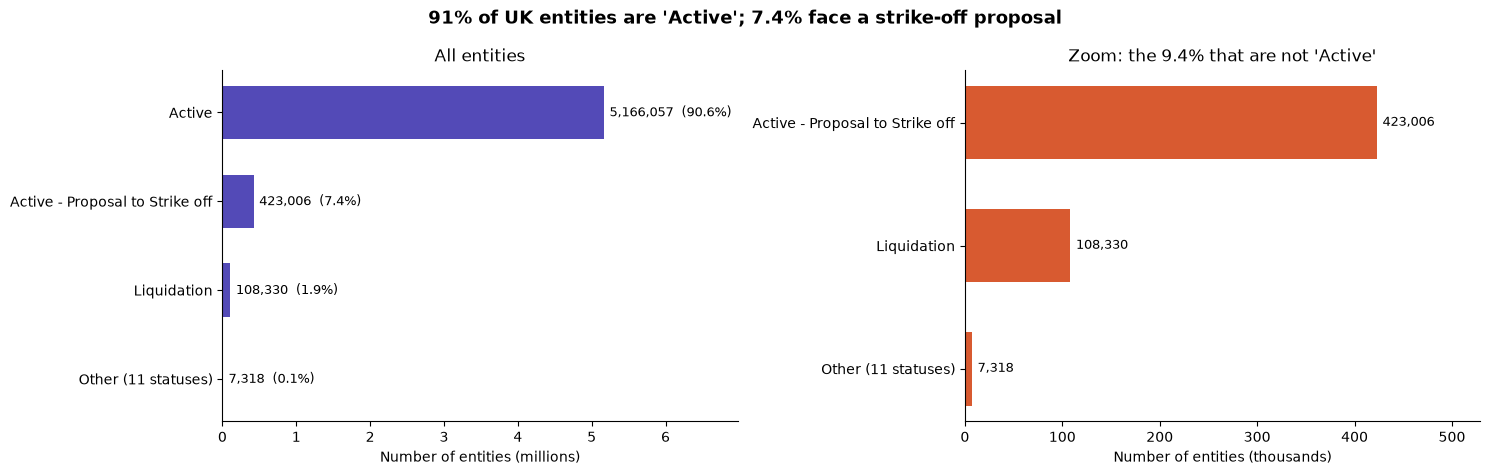

In [3]:
st = df["CompanyStatus"].value_counts()
st = st[st > 0]
top = st.head(3)
other = st.iloc[3:].sum()
plot = pd.concat([pd.Series({f"Other ({len(st) - 3} statuses)": other}), top.sort_values()])
share = plot / plot.sum()
labels = [f"{v:,.0f}  ({s:.1%})" for v, s in zip(plot.values, share.values)]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.8))

b1 = ax1.barh(plot.index.astype(str), plot.values / 1e6, color="#534AB7", height=0.6)
ax1.bar_label(b1, labels=labels, padding=4, fontsize=9)
ax1.set_xlim(0, plot.max() / 1e6 * 1.35)
ax1.set(title="All entities", xlabel="Number of entities (millions)")

zoom = plot.drop(top.index[0])
b2 = ax2.barh(zoom.index.astype(str), zoom.values / 1e3, color="#D85A30", height=0.6)
ax2.bar_label(b2, labels=[f"{v:,.0f}" for v in zoom.values], padding=4, fontsize=9)
ax2.set_xlim(0, zoom.max() / 1e3 * 1.25)
ax2.set(title=f"Zoom: the {1 - share[top.index[0]]:.1%} that are not '{top.index[0]}'",
        xlabel="Number of entities (thousands)")

for a in (ax1, ax2):
    a.spines[["top", "right"]].set_visible(False)
fig.suptitle(f"{share[top.index[0]]:.0%} of UK entities are '{top.index[0]}'; "
             f"{share.get('Active - Proposal to Strike off', 0):.1%} face a strike-off proposal",
             fontsize=13, weight="bold")
fig.tight_layout()
fig.savefig(FIG / "eda_02_company_status.png", dpi=200, bbox_inches="tight")
plt.show()

In [4]:
import seaborn as sns
from matplotlib.ticker import PercentFormatter, FuncFormatter

cols = ["sic_section", "in_scope", "is_active", "accounts_overdue", "company_age_years", "CompanyStatus"]
r = pd.read_parquet(DATA / "shellscope_companies.parquet", columns=cols)
print(r["sic_section"].value_counts().head(25))

SIC_NAMES = {"A": "Agriculture", "B": "Mining", "C": "Manufacturing", "D": "Energy supply",
             "E": "Water & waste", "F": "Construction", "G": "Wholesale & retail", "H": "Transport",
             "I": "Hotels & food", "J": "Info & comms", "K": "Finance & insurance", "L": "Real estate",
             "M": "Professional services", "N": "Admin & support", "O": "Public admin", "P": "Education",
             "Q": "Health & social", "R": "Arts & recreation", "S": "Other services",
             "T": "Households", "U": "Extraterritorial"}

sic_section
G                743696
M                676018
L                633620
F                571866
J                475327
N                394042
I                299004
None supplied    247820
C                235344
S                234864
Q                230740
K                230692
H                156102
R                131211
T                128100
P                112525
Dormant          104507
A                 44054
E                 18313
D                 17845
O                 10048
B                  8356
U                   617
Name: count, dtype: int64


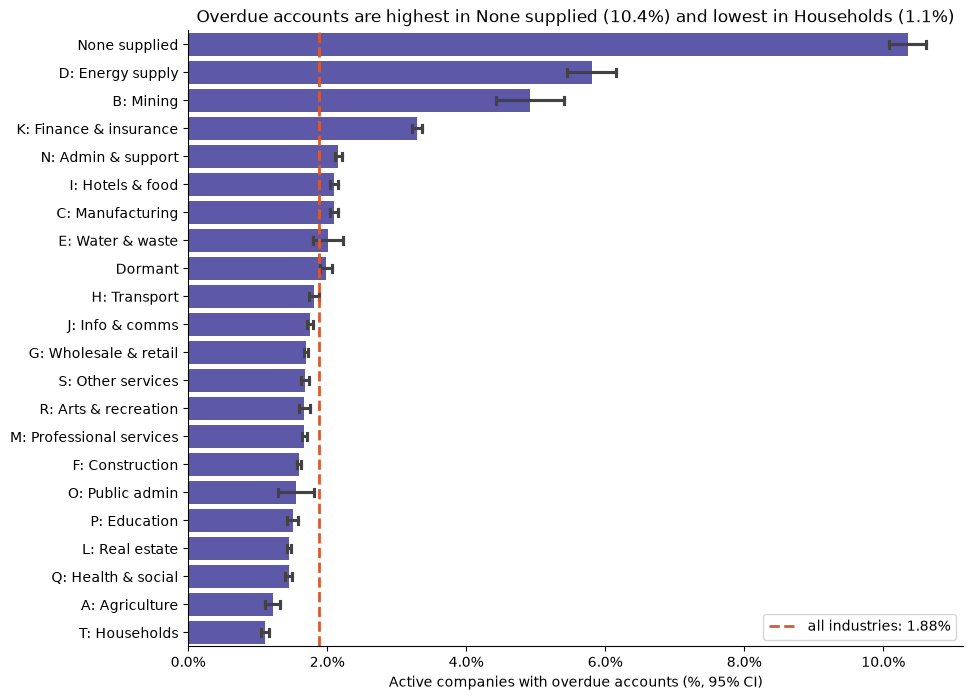

industry
None supplied               10.35
D: Energy supply             5.80
B: Mining                    4.92
K: Finance & insurance       3.30
N: Admin & support           2.16
I: Hotels & food             2.10
C: Manufacturing             2.10
E: Water & waste             2.01
Dormant                      1.98
H: Transport                 1.81
J: Info & comms              1.75
G: Wholesale & retail        1.70
S: Other services            1.68
R: Arts & recreation         1.67
M: Professional services     1.67
F: Construction              1.59
O: Public admin              1.55
P: Education                 1.50
L: Real estate               1.45
Q: Health & social           1.45
A: Agriculture               1.21
T: Households                1.11
Name: accounts_overdue, dtype: float64


In [5]:
od = r.loc[r["in_scope"] & r["is_active"], ["sic_section", "accounts_overdue"]].copy()
od["accounts_overdue"] = od["accounts_overdue"].astype(int)
od["sic_section"] = od["sic_section"].astype(str)
od["industry"] = od["sic_section"].map(lambda s: f"{s}: {SIC_NAMES[s]}" if s in SIC_NAMES else s)

n_by = od["industry"].value_counts()
od = od[od["industry"].isin(n_by[n_by >= 1000].index)]

rates = od.groupby("industry")["accounts_overdue"].mean().sort_values(ascending=False)
base = od["accounts_overdue"].mean()

fig, ax = plt.subplots(figsize=(10, 8))
sns.barplot(data=od, y="industry", x="accounts_overdue", order=rates.index,
            errorbar=("se", 1.96), color="#534AB7", capsize=0.25, ax=ax)
ax.axvline(base, color="#D85A30", ls="--", lw=2, label=f"all industries: {base:.2%}")
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set(xlabel="Active companies with overdue accounts (%, 95% CI)", ylabel="")
ax.set_title(f"Overdue accounts are highest in {rates.index[0].split(': ')[-1]} "
             f"({rates.iloc[0]:.1%}) and lowest in {rates.index[-1].split(': ')[-1]} ({rates.iloc[-1]:.1%})")
ax.legend(loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
fig.savefig(FIG / "eda_04_overdue_by_industry.png", dpi=200, bbox_inches="tight")
plt.show()
print((rates * 100).round(2))

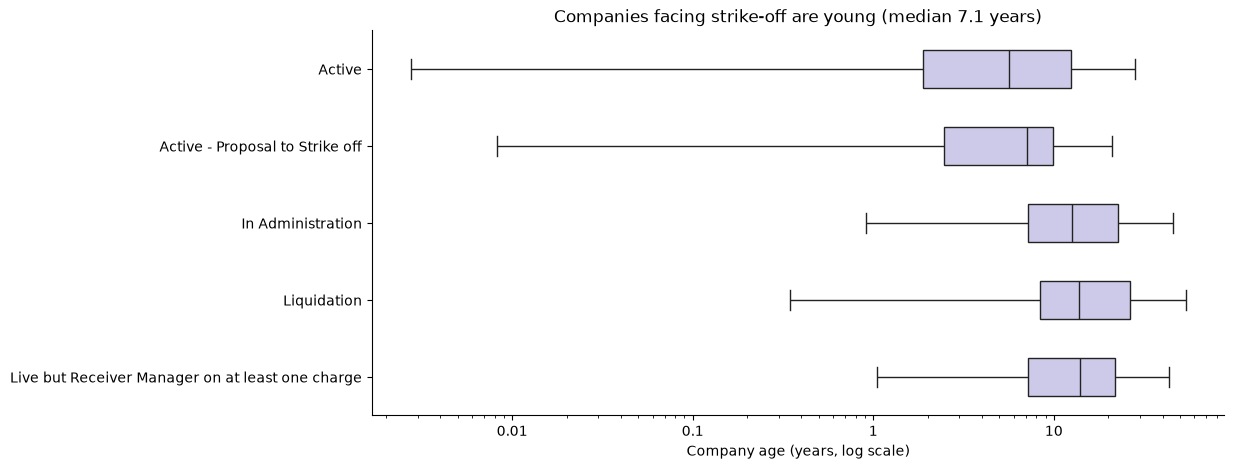

CompanyStatus
Active                                               5.62
Active - Proposal to Strike off                      7.15
In Administration                                   12.65
Liquidation                                         13.79
Live but Receiver Manager on at least one charge    14.00
Name: company_age_years, dtype: float64


In [6]:
b = r.loc[r["company_age_years"] > 0, ["CompanyStatus", "company_age_years"]].dropna()
b["CompanyStatus"] = b["CompanyStatus"].astype(str)
top5 = b["CompanyStatus"].value_counts().head(5).index
b = b[b["CompanyStatus"].isin(top5)]
order = b.groupby("CompanyStatus")["company_age_years"].median().sort_values().index
meds = b.groupby("CompanyStatus")["company_age_years"].median()

fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=b, x="company_age_years", y="CompanyStatus", order=order,
            showfliers=False, color="#C9C5EE", width=0.5, linecolor="#222", ax=ax)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
ax.set(xlabel="Company age (years, log scale)", ylabel="")
ax.set_title(f"Companies facing strike-off are young (median "
             f"{meds.get('Active - Proposal to Strike off', float('nan')):.1f} years)")
ax.spines[["top", "right"]].set_visible(False)
fig.savefig(FIG / "eda_05_age_by_status.png", dpi=200, bbox_inches="tight")
plt.show()
print(meds.round(2).sort_values())

In [3]:
import matplotlib.dates as mdates
df = pd.read_parquet(DATA / "shellscope_companies.parquet", columns=["IncorporationDate", "glasgow"])
inc = df.loc[(df["IncorporationDate"] >= "2000-01-01") &
             (df["IncorporationDate"] < "2026-10-01")].copy()
monthly = inc.set_index("IncorporationDate").resample("MS").size()
roll = monthly.rolling(12).mean()
print(monthly.tail(3)); print(len(monthly))

IncorporationDate
2026-07-01    68744
2026-08-01    58697
2026-09-01    68766
Freq: MS, dtype: int64
321


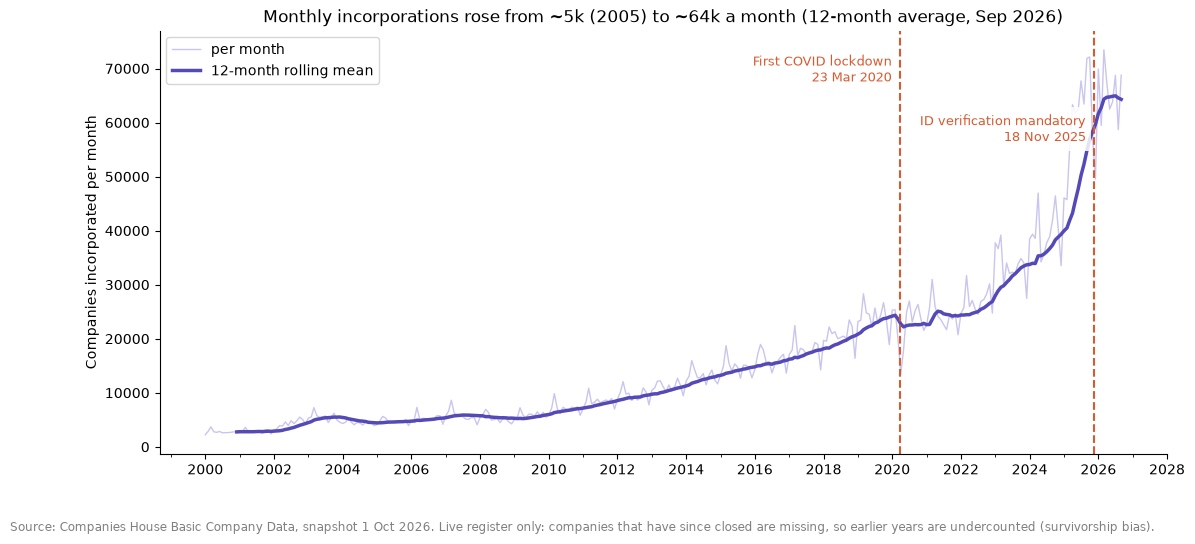

In [4]:
fig, ax = plt.subplots(figsize=(13, 5.5))
ax.plot(monthly.index, monthly.values, color="#C9C5EE", lw=1, label="per month")
ax.plot(roll.index, roll.values, color="#534AB7", lw=2.5, label="12-month rolling mean")

events = [("2020-03-23", "First COVID lockdown\n23 Mar 2020", 0.95),
          ("2025-11-18", "ID verification mandatory\n18 Nov 2025", 0.80)]
for d, txt, h in events:
    d = pd.Timestamp(d)
    ax.axvline(d, color="#D85A30", ls="--", lw=1.5)
    ax.annotate(txt, xy=(d, monthly.max() * h), xytext=(-6, 0), textcoords="offset points",
                ha="right", va="center", fontsize=9.5, color="#D85A30",
                bbox=dict(fc="white", ec="none", alpha=0.85))

ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_minor_locator(mdates.YearLocator(1))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_ylabel("Companies incorporated per month")
ax.set_title(f"Monthly incorporations rose from ~{roll.loc['2005-12-01']/1000:.0f}k (2005) "
             f"to ~{roll.iloc[-1]/1000:.0f}k a month (12-month average, Sep 2026)")
ax.legend(loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.01, -0.03, "Source: Companies House Basic Company Data, snapshot 1 Oct 2026. Live register only: "
         "companies that have since closed are missing, so earlier years are undercounted (survivorship bias).",
         fontsize=8.5, color="gray")
fig.savefig(FIG / "eda_06_incorporations_trend.png", dpi=200, bbox_inches="tight")
plt.show()

region
Glasgow (G)      233.0
Rest of UK     14486.0
dtype: float64
region             Glasgow (G)  Rest of UK
IncorporationDate                         
2026-07-01               435.2       441.3
2026-08-01               433.0       438.6
2026-09-01               431.6       436.9


NameError: name 'sns' is not defined

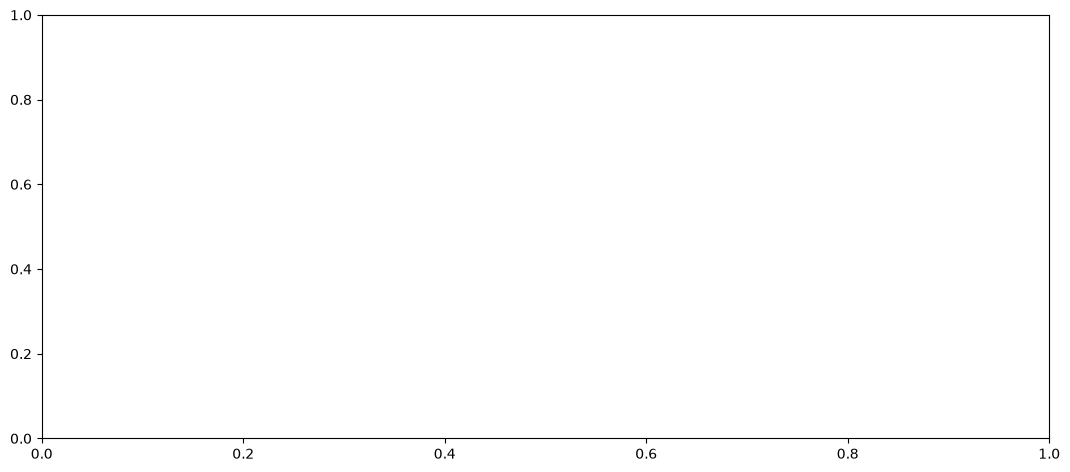

In [5]:
#flagow vc uk
inc["region"] = np.where(inc["glasgow"].fillna(False).astype(bool), "Glasgow (G)", "Rest of UK")

m = pd.crosstab(inc["IncorporationDate"].dt.to_period("M"), inc["region"])
m.index = m.index.to_timestamp()
m = m.asfreq("MS", fill_value=0)

sm = m.rolling(12).mean()
base = m.loc["2015"].mean()
idx = 100 * sm / base
print(base.round(0)); print(idx.tail(3).round(1))

long = (idx.reset_index()
           .melt(id_vars="IncorporationDate", var_name="region", value_name="index")
           .dropna())

fig, ax = plt.subplots(figsize=(13, 5.5))
sns.lineplot(data=long, x="IncorporationDate", y="index", hue="region",
             hue_order=["Rest of UK", "Glasgow (G)"], palette=["#534AB7", "#1D9E75"], lw=2.2, ax=ax)
ax.axhline(100, color="gray", ls=":", lw=1)
ax.axvspan(pd.Timestamp("2015-01-01"), pd.Timestamp("2015-12-31"), color="gray", alpha=0.12)
ax.axvline(pd.Timestamp("2025-11-18"), color="#D85A30", ls="--", lw=1.5)
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
g_last, uk_last = idx["Glasgow (G)"].iloc[-1], idx["Rest of UK"].iloc[-1]
ax.set(xlabel="", ylabel="Index (2015 monthly average = 100)",
       title=f"Since 2015, monthly incorporations changed {g_last-100:+.0f}% in Glasgow vs "
             f"{uk_last-100:+.0f}% in the rest of the UK (12-month averages)")
ax.legend(title=None, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.01, -0.03, f"Base: 2015 average = {base['Glasgow (G)']:.0f}/month (Glasgow), "
         f"{base['Rest of UK']:,.0f}/month (rest of UK). Live companies only; indexing assumes similar "
         "closure rates in both regions.", fontsize=8.5, color="gray")
fig.savefig(FIG / "eda_07_glasgow_vs_uk_indexed.png", dpi=200, bbox_inches="tight")
plt.show()